In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import lightgbm as lgbm

In [22]:
df = pd.read_csv('creditcard.csv')

print(df.head())
print(df.shape)
print(df.info())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


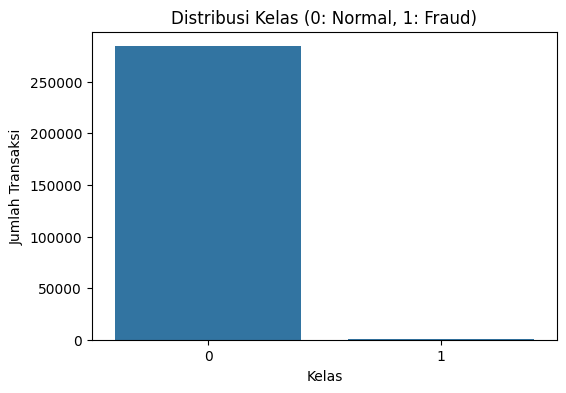

In [23]:
class_counts = df['Class'].value_counts()
class_percentage = df['Class'].value_counts(normalize=True) * 100

print(class_counts)
print(class_percentage)

plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribusi Kelas (0: Normal, 1: Fraud)')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Transaksi')
plt.show()

In [24]:
def across_col_feat(df):
    features = [feat for feat in df.columns if 'V' in feat]
    df['V_Sum'] = df[features].sum(axis=1)
    df['V_Min'] = df[features].min(axis=1)
    df['V_Max'] = df[features].max(axis=1)
    df['V_Avg'] = df[features].mean(axis=1)
    df['V_Std'] = df[features].std(axis=1)
    df['V_Pos'] = df[features].gt(0).sum(axis=1)
    df['V_Neg'] = df[features].lt(0).sum(axis=1)
    df['V_Range'] = abs(df['V_Min'] - df['V_Max'])
    return df

df = across_col_feat(df)

In [25]:
rscale = RobustScaler()
X = df.drop(['Class'], axis=1)
y = df['Class']

X[X.columns] = rscale.fit_transform(X[X.columns])

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [27]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_res.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    227451
1    227451
Name: count, dtype: int64


In [28]:
catboost_params = {
    'n_estimators': 500,
    'learning_rate': 0.03,
    'one_hot_max_size': 12,
    'depth': 4,
    'l2_leaf_reg': 0.014,
    'colsample_bylevel': 0.06,
    'min_data_in_leaf': 12,
    'boosting_type': 'Plain',
    'bootstrap_type': 'Bernoulli',
    'verbose': False
}

xgb_params = {
    'n_estimators': 500,
    'min_child_weight': 96,
    'max_depth': 7,
    'learning_rate': 0.18,
    'subsample': 0.95,
    'colsample_bytree': 0.95,
    'reg_lambda': 1.50,
    'reg_alpha': 1.50,
    'gamma': 1.50,
    'max_bin': 512,
    'random_state': 42,
    'objective': 'binary:logistic',
    'tree_method': 'hist',
    'eval_metric': 'auc'
}

lgbm_params = {
    'n_estimators': 500,
    'num_rounds': 274,
    'learning_rate': 0.1,
    'num_leaves': 195,
    'max_depth': 9,
    'min_data_in_leaf': 46,
    'lambda_l1': 0.01,
    'lambda_l2': 0.6,
    'min_gain_to_split': 1.42,
    'bagging_fraction': 0.45,
    'feature_fraction': 0.3,
    'verbose': -1
}

model_cb = CatBoostClassifier(**catboost_params)
model_xgb = XGBClassifier(**xgb_params)
model_lgbm = lgbm.LGBMClassifier(**lgbm_params)

model_cb.fit(X_train, y_train)
model_xgb.fit(X_train, y_train)
model_lgbm.fit(X_train, y_train)

,num_leaves,195
,max_depth,9
,n_estimators,500
,num_rounds,274
,min_data_in_leaf,46
,lambda_l1,0.01
,lambda_l2,0.6
,min_gain_to_split,1.42
,bagging_fraction,0.45
,feature_fraction,0.3
,verbose,-1


Classification Report (Tanpa Resampling):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.91      0.81      0.85        98

    accuracy                           1.00     56962
   macro avg       0.95      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962

AUC-ROC Score: 0.9744643144258265


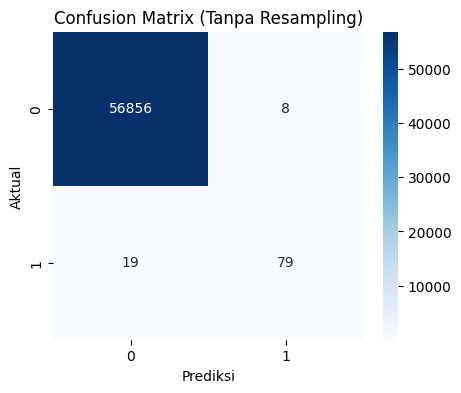

In [29]:
pred_cb = model_cb.predict_proba(X_test)[:, 1]
pred_xgb = model_xgb.predict_proba(X_test)[:, 1]
pred_lgbm = model_lgbm.predict_proba(X_test)[:, 1]

final_prob_no_res = pred_cb * 0.35 + pred_xgb * 0.35 + pred_lgbm * 0.30
final_pred_no_res = (final_prob_no_res >= 0.5).astype(int)

print("Classification Report (Tanpa Resampling):")
print(classification_report(y_test, final_pred_no_res))
print("AUC-ROC Score:", roc_auc_score(y_test, final_prob_no_res))

cm = confusion_matrix(y_test, final_pred_no_res)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Tanpa Resampling)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [30]:
model_cb_res = CatBoostClassifier(**catboost_params)
model_xgb_res = XGBClassifier(**xgb_params)
model_lgbm_res = lgbm.LGBMClassifier(**lgbm_params)

model_cb_res.fit(X_train_res, y_train_res)
model_xgb_res.fit(X_train_res, y_train_res)
model_lgbm_res.fit(X_train_res, y_train_res)

,num_leaves,195
,max_depth,9
,n_estimators,500
,num_rounds,274
,min_data_in_leaf,46
,lambda_l1,0.01
,lambda_l2,0.6
,min_gain_to_split,1.42
,bagging_fraction,0.45
,feature_fraction,0.3
,verbose,-1


Classification Report (Dengan SMOTE):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.66      0.90      0.76        98

    accuracy                           1.00     56962
   macro avg       0.83      0.95      0.88     56962
weighted avg       1.00      1.00      1.00     56962

AUC-ROC Score: 0.9798649552674192


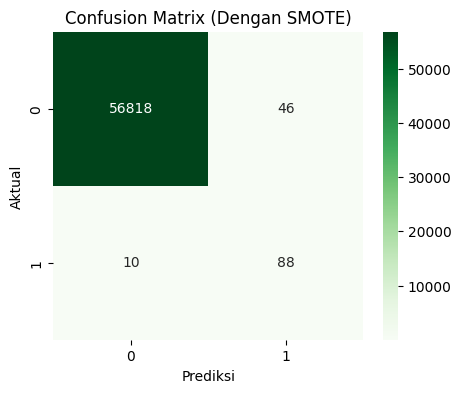

In [31]:
pred_cb_res = model_cb_res.predict_proba(X_test)[:, 1]
pred_xgb_res = model_xgb_res.predict_proba(X_test)[:, 1]
pred_lgbm_res = model_lgbm_res.predict_proba(X_test)[:, 1]

final_prob_res = pred_cb_res * 0.35 + pred_xgb_res * 0.35 + pred_lgbm_res * 0.30
final_pred_res = (final_prob_res >= 0.5).astype(int)

print("Classification Report (Dengan SMOTE):")
print(classification_report(y_test, final_pred_res))
print("AUC-ROC Score:", roc_auc_score(y_test, final_prob_res))

cm_res = confusion_matrix(y_test, final_pred_res)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_res, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix (Dengan SMOTE)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [32]:
metrics_summary = pd.DataFrame({
    'Model': ['Ensemble Tanpa Resampling', 'Ensemble Dengan SMOTE'],
    'Precision': [
        precision_score(y_test, final_pred_no_res),
        precision_score(y_test, final_pred_res)
    ],
    'Recall': [
        recall_score(y_test, final_pred_no_res),
        recall_score(y_test, final_pred_res)
    ],
    'F1-Score': [
        f1_score(y_test, final_pred_no_res),
        f1_score(y_test, final_pred_res)
    ],
    'AUC-ROC': [
        roc_auc_score(y_test, final_prob_no_res),
        roc_auc_score(y_test, final_prob_res)
    ]
})

print(metrics_summary)

                       Model  Precision    Recall  F1-Score   AUC-ROC
0  Ensemble Tanpa Resampling   0.908046  0.806122  0.854054  0.974464
1      Ensemble Dengan SMOTE   0.656716  0.897959  0.758621  0.979865
